In [30]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import seaborn as sns
from sqlalchemy import create_engine

# 1. Define your MySQL configuration credentials
DB_USER = "root"
DB_PASSWORD = "Manoj1297%40"
DB_HOST = "127.0.0.1"
DB_NAME = "tmdb"

# 2. Create the connection engine using PyMySQL driver
engine = create_engine(
    f"mysql+pymysql://{DB_USER}:{DB_PASSWORD}@{DB_HOST}/{DB_NAME}"
)

# Load all tables from your MySQL database into pandas DataFrames
movies_df = pd.read_sql("SELECT * FROM movies", engine)
genres_df = pd.read_sql("SELECT * FROM genres", engine)
movie_genres_df = pd.read_sql("SELECT * FROM movie_genres", engine)
cast_df = pd.read_sql("SELECT * FROM cast", engine)
crew_df = pd.read_sql("SELECT * FROM crew", engine)
movie_keywords_df = pd.read_sql("SELECT * FROM movie_keywords", engine)

# Set visual style
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

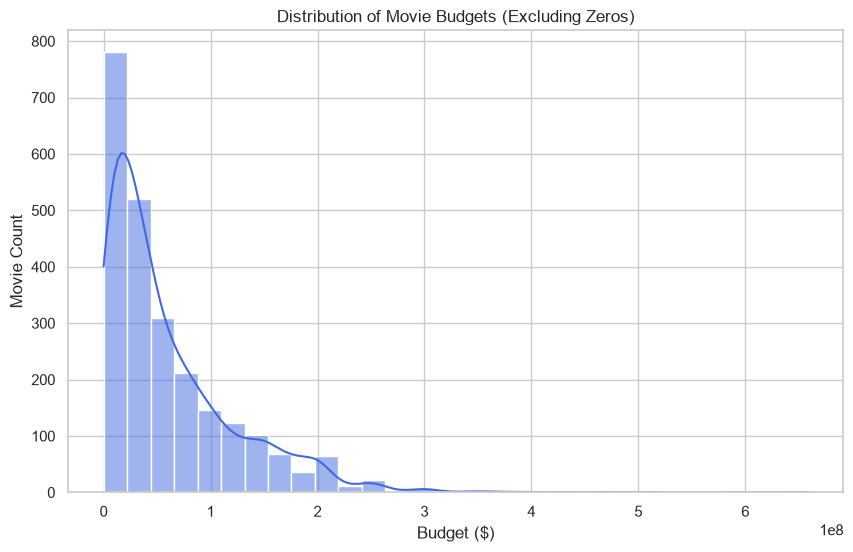

In [13]:
#1. Univariate Analysis
#A. Distribution of Movie Budgets
plt.figure(figsize=(10, 6))
sns.histplot(
    movies_df[movies_df['budget'] > 0]['budget'],
    kde=True,
    color='royalblue',
    bins=30,
)
plt.title('Distribution of Movie Budgets (Excluding Zeros)')
plt.xlabel('Budget ($)')
plt.ylabel('Movie Count')
plt.show()

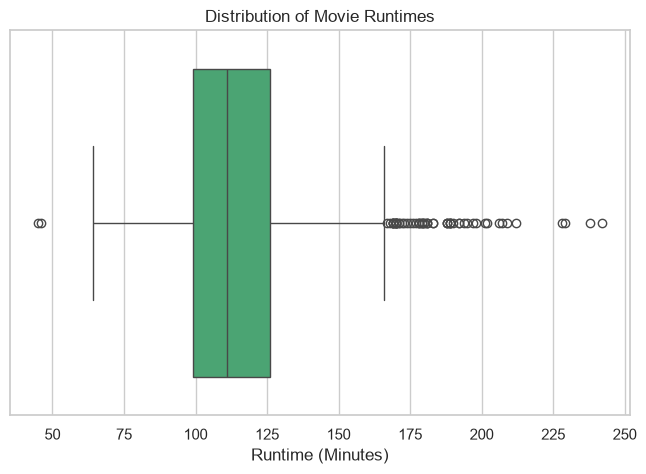

In [14]:
#B. Distribution of Runtimes
plt.figure(figsize=(8, 5))
sns.boxplot(x=movies_df[movies_df['runtime'] > 0]['runtime'], color='mediumseagreen')
plt.title('Distribution of Movie Runtimes')
plt.xlabel('Runtime (Minutes)')
plt.show()

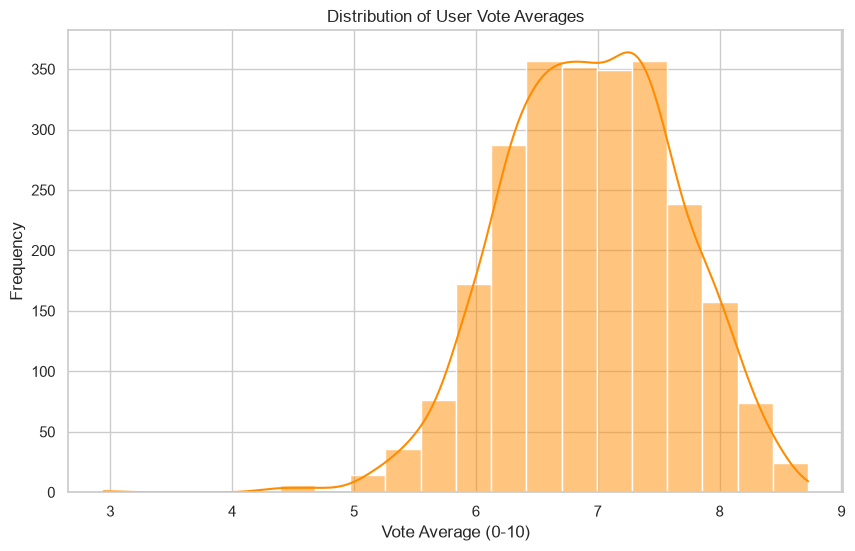

In [15]:
#C. Distribution of Vote Average Scores
plt.figure(figsize=(10, 6))
sns.histplot(
    movies_df[movies_df['vote_count'] > 10]['vote_average'],
    kde=True,
    color='darkorange',
    bins=20,
)
plt.title('Distribution of User Vote Averages')
plt.xlabel('Vote Average (0-10)')
plt.ylabel('Frequency')
plt.show()

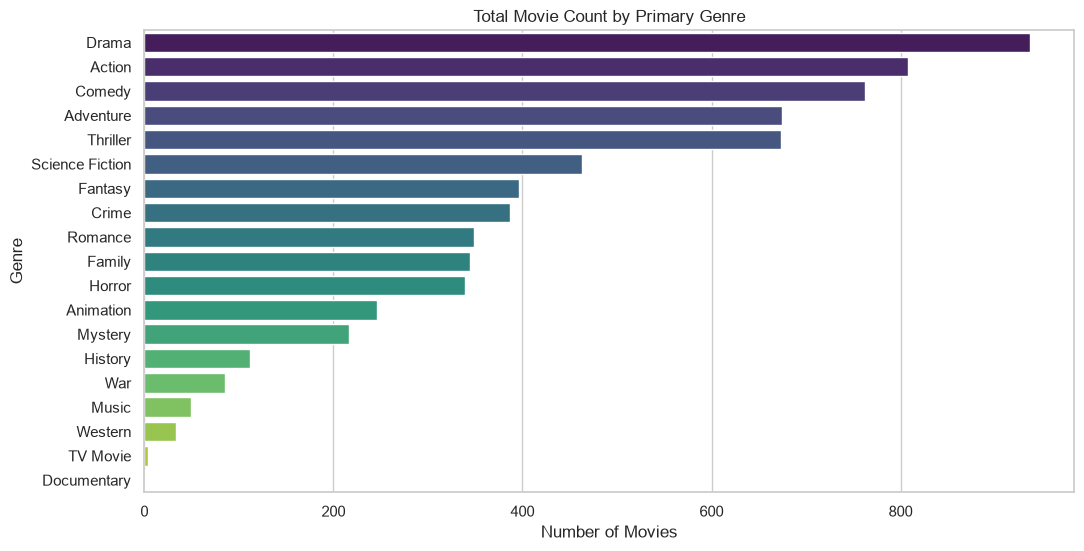

In [ ]:
#D. Count of Movies per Genre

# Merge tables to link each movie with its genres
primary_genre_df = (
    movies_df.merge(movie_genres_df, on="movie_id")
    .merge(genres_df, on="genre_id")
)

# Now your genre count code will work successfully
genre_counts = primary_genre_df["genre_name"].value_counts()
plt.figure(figsize=(12, 6))
sns.barplot(
    x=genre_counts.values, y=genre_counts.index, palette='viridis', hue=genre_counts.index, legend=False
)
plt.title('Total Movie Count by Primary Genre')
plt.xlabel('Number of Movies')
plt.ylabel('Genre')
plt.show()

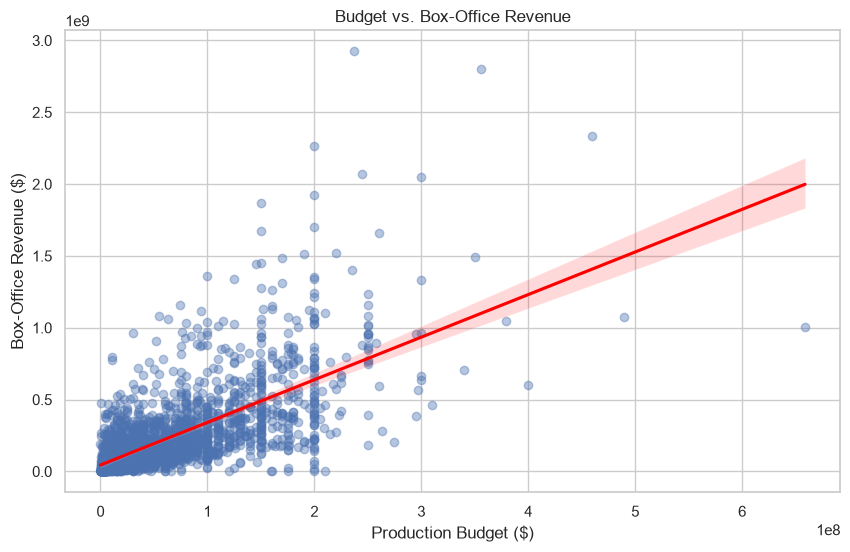

In [21]:
#2. Bivariate Analysis
#A. Budget vs. Revenue
valid_rev = movies_df[(movies_df['budget'] > 0) & (movies_df['revenue'] > 0)]
plt.figure(figsize=(10, 6))
sns.regplot(
    x='budget',
    y='revenue',
    data=valid_rev,
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'},
)
plt.title('Budget vs. Box-Office Revenue')
plt.xlabel('Production Budget ($)')
plt.ylabel('Box-Office Revenue ($)')
plt.show()

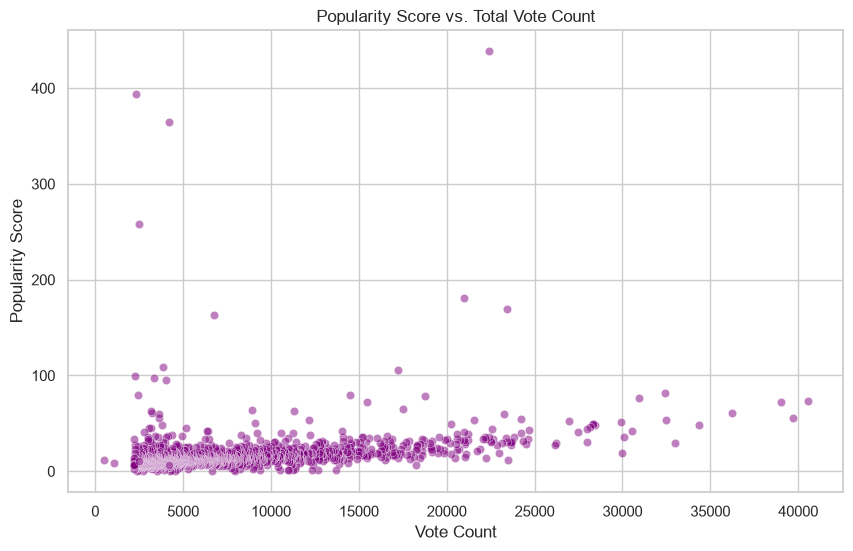

In [23]:
#B. Popularity vs. Vote Count
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x='vote_count',
    y='popularity',
    data=movies_df,
    alpha=0.5,
    color='purple',
)
plt.title('Popularity Score vs. Total Vote Count')
plt.xlabel('Vote Count')
plt.ylabel('Popularity Score')
plt.show()

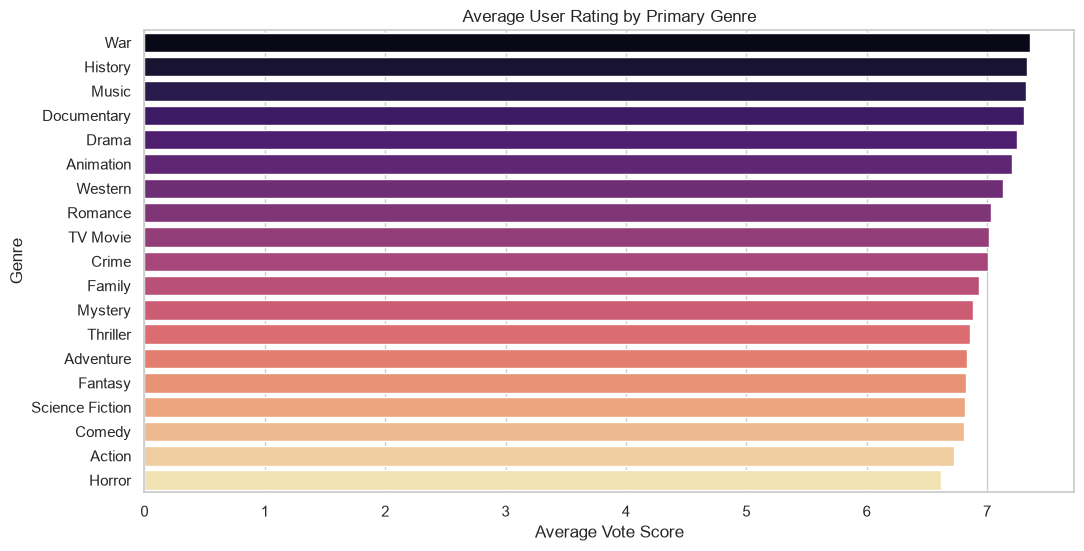

In [24]:
#C. Average Rating by Genre
avg_rating_genre = (
    primary_genre_df.groupby('genre_name')['vote_average']
    .mean()
    .sort_values(ascending=False)
)
plt.figure(figsize=(12, 6))
sns.barplot(
    x=avg_rating_genre.values, y=avg_rating_genre.index, palette='magma', hue=avg_rating_genre.index, legend=False
)
plt.title('Average User Rating by Primary Genre')
plt.xlabel('Average Vote Score')
plt.ylabel('Genre')
plt.show()

['movie_id', 'title', 'original_language', 'release_date', 'runtime', 'budget', 'revenue', 'popularity', 'vote_average', 'vote_count', 'status', 'overview']


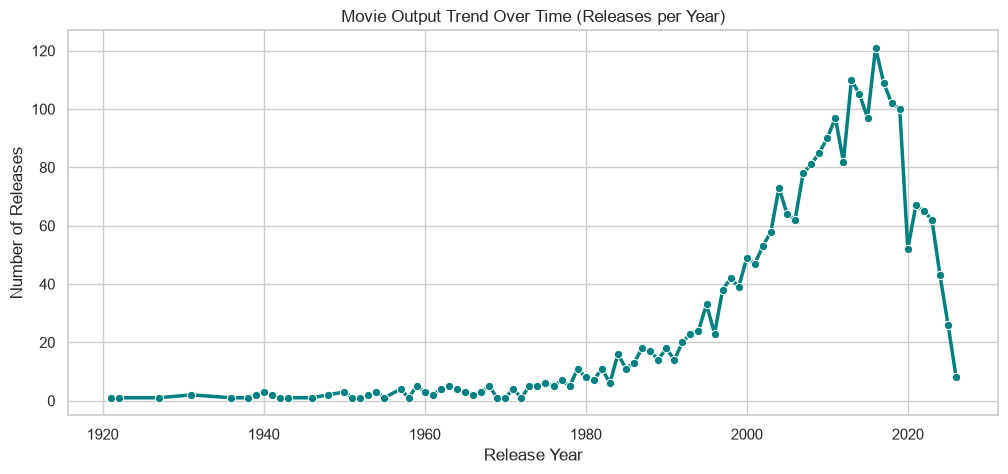

In [27]:
#D. Number of Movies Released per Year

print(movies_df.columns.tolist())
# If your column is 'release_date', extract the year like this:
movies_df["release_year"] = pd.to_datetime(
    movies_df["release_date"]
).dt.year
yearly_counts = movies_df['release_year'].value_counts().sort_index()
plt.figure(figsize=(12, 5))
sns.lineplot(
    x=yearly_counts.index,
    y=yearly_counts.values,
    marker='o',
    color='teal',
    linewidth=2.5,
)
plt.title('Movie Output Trend Over Time (Releases per Year)')
plt.xlabel('Release Year')
plt.ylabel('Number of Releases')
plt.show()

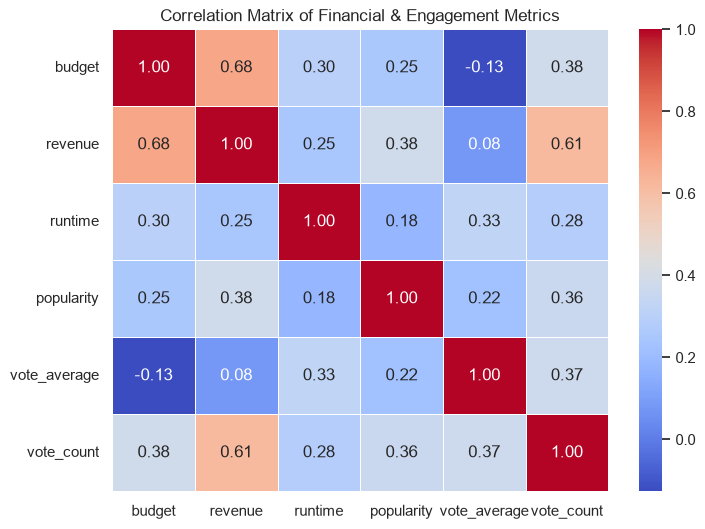

In [28]:
#3. Multivariate Analysis
#A. Correlation Heatmap
plt.figure(figsize=(8, 6))
numeric_cols = [
    'budget',
    'revenue',
    'runtime',
    'popularity',
    'vote_average',
    'vote_count',
]
corr_matrix = movies_df[numeric_cols].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Matrix of Financial & Engagement Metrics')
plt.show()

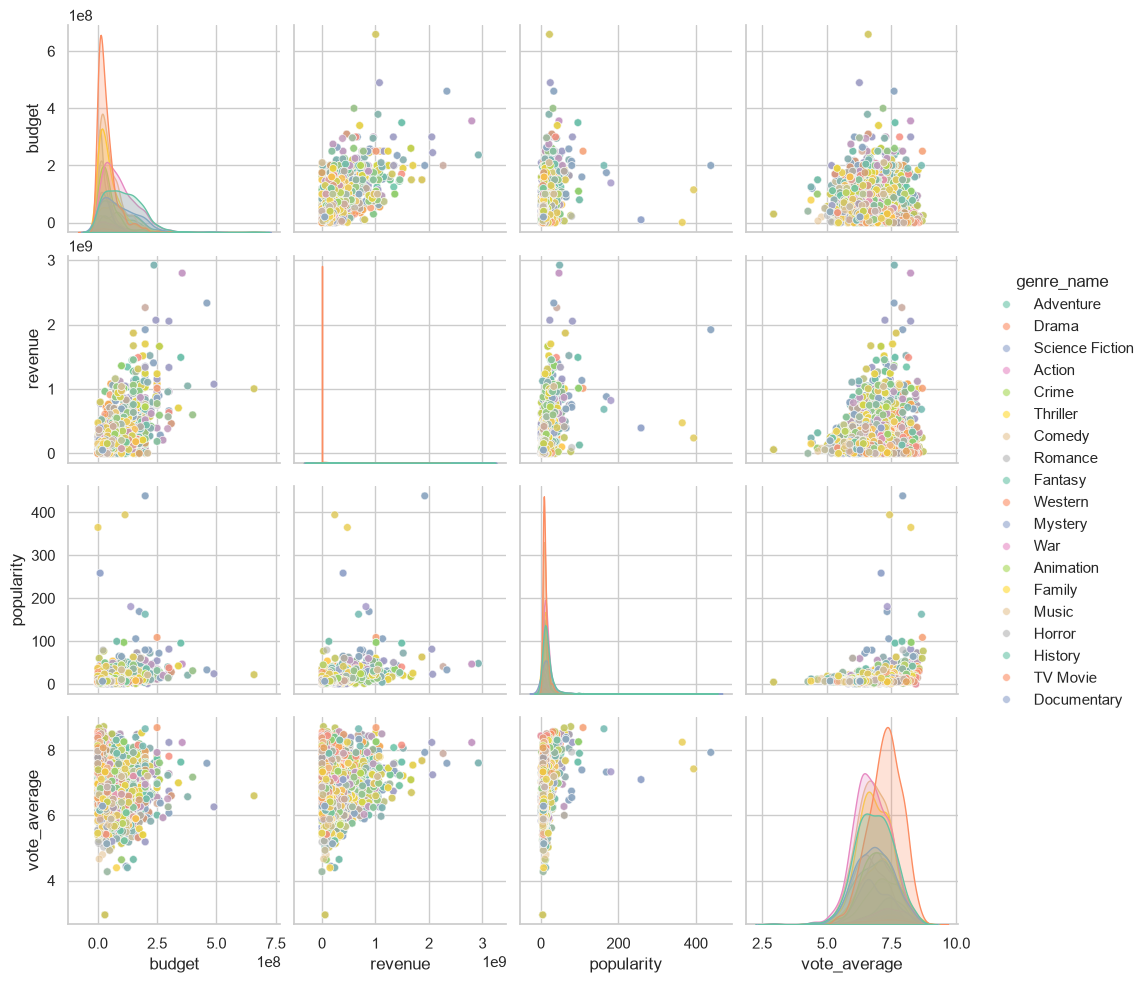

In [29]:
#B. Pairplot of Key Metrics Colored by Genre
sample_df = primary_genre_df.dropna(
    subset=['budget', 'revenue', 'popularity', 'vote_average']
)
sns.pairplot(
    sample_df[
        ['budget', 'revenue', 'popularity', 'vote_average', 'genre_name']
    ],
    hue='genre_name',
    palette='Set2',
    plot_kws={'alpha': 0.6, 's': 30},
)
plt.show()

In [48]:
#C. Budget vs. Revenue (Colored by Genre & Sized by Vote Count)
fig = px.scatter(
    valid_rev.merge(primary_genre_df[['movie_id', 'genre_name']], on='movie_id'),
    x='budget',
    y='revenue',
    color='genre_name',
    size='vote_count',
    hover_name='title',
    title='Budget vs Revenue by Genre (Sized by Vote Count)',
)
fig.show()

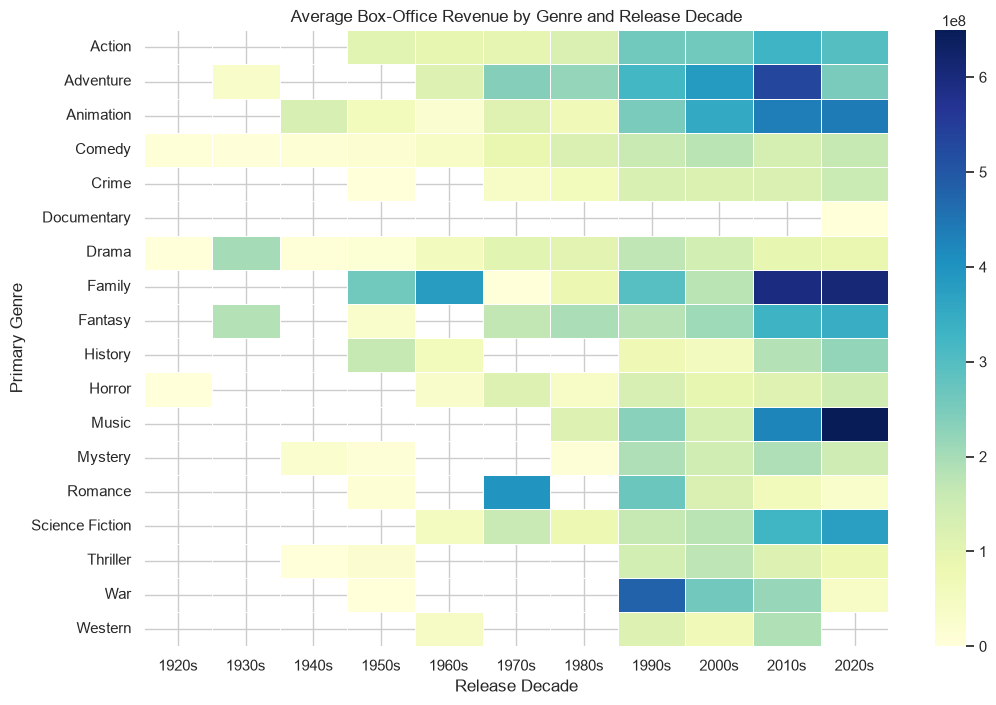

In [50]:
#D. Average Revenue by Genre and Release Decade
primary_genre_df['decade'] = (
    (primary_genre_df['release_year'] // 10) * 10
).astype(str) + 's'
pivot_rev = primary_genre_df.pivot_table(
    index='genre_name',
    columns='decade',
    values='revenue',
    aggfunc='mean',
)

plt.figure(figsize=(12, 8))
sns.heatmap(pivot_rev, cmap='YlGnBu', annot=False, fmt='.0f', linewidths=0.5)
plt.title('Average Box-Office Revenue by Genre and Release Decade')
plt.xlabel('Release Decade')
plt.ylabel('Primary Genre')
plt.show()